# Workstream B — Edge weights and thresholds

**Owner:** Project 2 (modules without magnitude). **Question:** what does the threshold remove, and how much of edge weight is signal?

Week 3 EDA Plan, items B1–B7. Every figure is regenerated from the local cache (`data/cache/`) with `eda_shared` v0.1.1-eda; no network calls once the cache exists.

Conventions used throughout (EDA Plan, *Definitions*):

- `fafb`: FlyWire 783, annotations v3.2.0, Buhmann synapses. `malecns`: male CNS v1.0, Traced, synapse confidence ≥ 0.5, **brain part only** (`in_brain == True`) and the edges among those neurons.
- Populations: `all`, `central` (`is_optic == False`), `optic`. An edge belongs to a population when both of its neurons do.
- Thresholds: τ ∈ {1, 5, 10, 31} synapses; relative f ∈ {0.9%, 2.6%} of the target's input, with `total_in_syn` computed once at τ = 1 over the dataset and never after thresholding.
- Where an item does not name a threshold, τ = 10.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists())
sys.path.insert(0, str(ROOT))
import os; os.chdir(ROOT)

In [2]:
import json, logging, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import src
import eda_shared
from src import fetch_fafb, fetch_malecns, eda_b
from src.populations import eda_tables, population_ids, restrict
from src.validate import validate_dataset, assert_interchangeable
from src.plotting import COLORS, LINESTYLES, LABELS, style, save, save_table

warnings.filterwarnings("ignore", category=FutureWarning)
logging.basicConfig(level=logging.INFO, format="%(message)s")
style()
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 3)
print("eda_shared", eda_shared.__version__)

N = {}   # every number quoted in reports/eda_B.md comes from here

eda_shared 0.1.1-eda


## Step 0 — load the cache and validate

In [3]:
raw = {"fafb": fetch_fafb.load(), "malecns": fetch_malecns.load()}
for ds, (n, e, r) in raw.items():
    validate_dataset(n, e, r)
for i in range(3):
    assert_interchangeable(raw["fafb"][i], raw["malecns"][i])
print("all validators and assert_interchangeable pass")

step0 = pd.DataFrame({
    "neurons": {ds: len(t[0]) for ds, t in raw.items()},
    "edges_tau1": {ds: len(t[1]) for ds, t in raw.items()},
    "edges_ge5": {ds: int((t[1].syn_count >= 5).sum()) for ds, t in raw.items()},
})
N["step0"] = step0.to_dict()
step0

cache hit  fafb_neurons_783_ann3.2.0.parquet


cache hit  fafb_edges_783_buhmann_min1.parquet


cache hit  fafb_edgeroi_783_buhmann_min1.parquet


cache hit  malecns_neurons_v1.0_traced.parquet


cache hit  malecns_edges_v1.0_traced_min1_conf0.5.parquet


cache hit  malecns_edgeroi_v1.0_traced_min1_conf0.5.parquet


all validators and assert_interchangeable pass


,neurons,edges_tau1,edges_ge5
fafb,139262,15091983,2700513
malecns,165122,25563096,6235649


In [4]:
# EDA tables: flags from eda_shared, malecns cut to its brain part, frac with the fixed denominator
T = {}
for ds, (n, e, r) in raw.items():
    T[ds] = eda_tables(n, e)
    print(ds, "EDA neurons", len(T[ds][0]), "edges", len(T[ds][1]))
N["eda_population_sizes"] = {ds: {p: len(population_ids(T[ds][0], p)) for p in ("all", "central", "optic")} for ds in T}
N["eda_population_sizes"]

fafb EDA neurons 139262 edges 15091983


malecns EDA neurons 141996 edges 21265290


{'fafb': {'all': 139262, 'central': 44494, 'optic': 94768},
 'malecns': {'all': 141996, 'central': 43623, 'optic': 98373}}

## B1 — How strong are edges

Data: edges at τ = 1, populations all and central; edgeroi for the aggregation check (D8).

In [5]:
SELF_LOGGED = {"fafb": 0, "malecns": 101}      # from the fetch logs (fetch_fafb / fetch_malecns)
b1 = {}
for ds, (n, e, r) in raw.items():
    if ds == "malecns":                        # edgeroi restricted the same way as edges
        keep = pd.Index(T[ds][0]["neuron_id"])
        r = r[r.pre_id.isin(keep) & r.post_id.isin(keep)]
    b1[ds] = eda_b.b1_counts(T[ds][1], r, SELF_LOGGED[ds])
b1 = pd.DataFrame(b1)
N["B1_counts"] = b1.to_dict()
save_table(b1.reset_index(names="count"), "B1_counts.csv")
b1

,fafb,malecns
edges,1.509e+07,2.127e+07
synapses,5.449e+07,9.731e+07
self_connections_in_table,0.000e+00,0.000e+00
self_connections_dropped_logged,0.000e+00,1.010e+02
edgeroi_rows,1.685e+07,2.419e+07
edgeroi_rows_per_edge,1.116e+00,1.138e+00
edgeroi_synapses,5.449e+07,9.731e+07


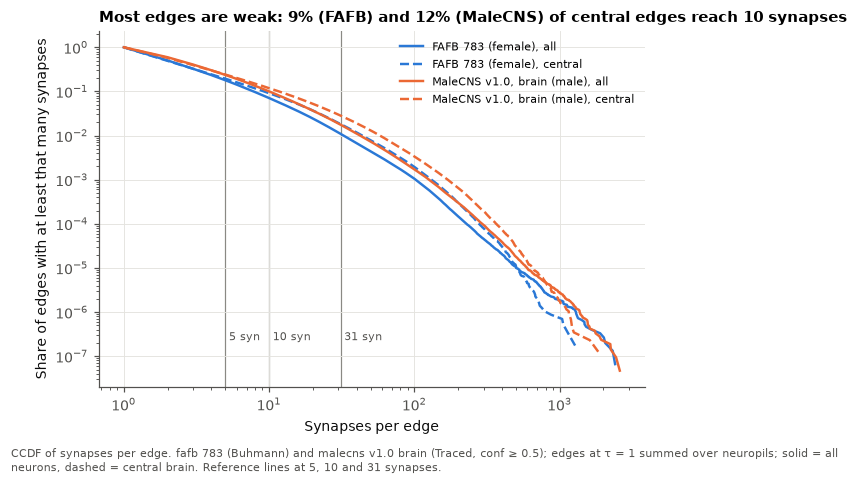

In [6]:
fig, ax = plt.subplots(figsize=(6.4, 4.2))
for ds, (n, e) in T.items():
    for pop in ("all", "central"):
        w = restrict(e, population_ids(n, pop))["syn_count"]
        c = eda_b.ccdf(w)
        ax.plot(c.x, c.share, color=COLORS[ds], ls=LINESTYLES[pop], lw=1.6,
                label=f"{LABELS[ds]}, {pop}")
        N.setdefault("B1_share_ge", {})[f"{ds}_{pop}"] = {t: float((w >= t).mean()) for t in (5, 10, 31)}
for t in (5, 10, 31):
    ax.axvline(t, color=COLORS["muted"], lw=0.8, zorder=0)
    ax.text(t * 1.06, 2e-7, f"{t} syn", ha="left", va="bottom", fontsize=7.5, color="#52514e")
ax.set(xscale="log", yscale="log", xlabel="Synapses per edge", ylabel="Share of edges with at least that many synapses")
f10 = N["B1_share_ge"]["fafb_central"][10]; m10 = N["B1_share_ge"]["malecns_central"][10]
ax.set_title(f"Most edges are weak: {f10:.0%} (FAFB) and {m10:.0%} (MaleCNS) of central edges reach 10 synapses", loc="left")
ax.legend(fontsize=7.5)
save(fig, "B1", ["fafb", "malecns"], "min1", ["all", "central"],
     "CCDF of synapses per edge. fafb 783 (Buhmann) and malecns v1.0 brain (Traced, conf ≥ 0.5); edges at τ = 1 "
     "summed over neuropils; solid = all neurons, dashed = central brain. Reference lines at 5, 10 and 31 synapses.")
plt.show()

## B2 — The threshold table

Degrees count partners inside the population and include zeros: every neuron of the population is a row (`basic_features` convention). `isolated` = no edge left inside the population.

In [7]:
b2 = pd.concat([eda_b.b2_threshold_table(n, e, pop).assign(dataset=ds)
                for ds, (n, e) in T.items() for pop in ("all", "central", "optic")], ignore_index=True)
b2 = b2[["dataset"] + [c for c in b2.columns if c != "dataset"]]
save_table(b2, "B2_threshold_table.csv")
N["B2"] = b2.set_index(["dataset", "population", "criterion"])[
    ["edges", "edges_pct", "synapses_pct", "neurons_isolated", "isolated_pct",
     "median_in_degree", "median_out_degree", "p99_out_degree"]].round(3).reset_index().to_dict("records")
b2[b2.population == "central"]

,dataset,population,neurons,criterion,edges,edges_pct,synapses,synapses_pct,neurons_connected,neurons_isolated,isolated_pct,median_in_degree,median_out_degree,p99_out_degree
6,fafb,central,44494,>= 1 syn,5725259,100.000,24153951,100.000,43869,625,1.405,89.0,97.0,648.07
7,fafb,central,44494,>= 5 syn,1110703,19.400,16797967,69.545,42775,1719,3.863,10.0,13.0,177.00
8,fafb,central,44494,>= 10 syn,521283,9.105,12979407,53.736,39578,4916,11.049,4.0,5.0,100.00
9,fafb,central,44494,>= 31 syn,104207,1.820,6242222,25.843,23347,21147,47.528,0.0,0.0,27.00
10,fafb,central,44494,>= 0.9% of input,1000229,17.470,11661137,48.278,43831,663,1.490,23.0,12.0,179.00
11,fafb,central,44494,>= 2.6% of input,285223,4.982,5402313,22.366,43037,1457,3.275,6.0,1.0,79.00
24,malecns,central,43623,>= 1 syn,8652823,100.000,46290562,100.000,43614,9,0.021,153.0,158.0,853.00
25,malecns,central,43623,>= 5 syn,2084517,24.091,35000250,75.610,43416,207,0.475,26.0,33.0,261.00
26,malecns,central,43623,>= 10 syn,1025959,11.857,28130778,60.770,42906,717,1.644,9.0,13.0,157.00
27,malecns,central,43623,>= 31 syn,245216,2.834,15407890,33.285,36232,7391,16.943,1.0,2.0,48.00


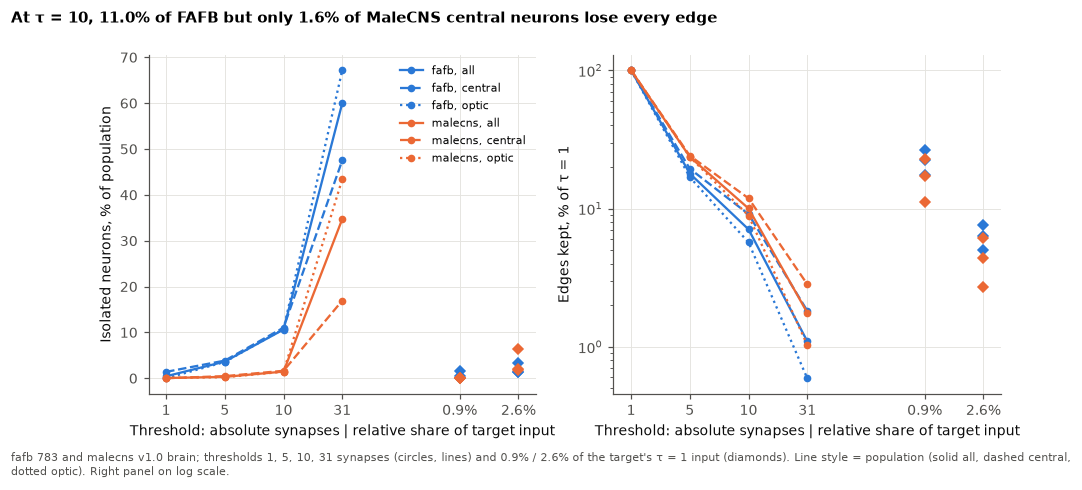

In [8]:
order = [">= 1 syn", ">= 5 syn", ">= 10 syn", ">= 31 syn", ">= 0.9% of input", ">= 2.6% of input"]
xpos = {c: i for i, c in enumerate(order[:4])} | {order[4]: 5, order[5]: 6}   # gap before the relative ones
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col, ylabel in [(axes[0], "isolated_pct", "Isolated neurons, % of population"),
                        (axes[1], "edges_pct", "Edges kept, % of τ = 1")]:
    for (ds, pop), g in b2.groupby(["dataset", "population"]):
        g = g.set_index("criterion").loc[order]
        x = [xpos[c] for c in order]
        ax.plot(x[:4], g[col].iloc[:4], color=COLORS[ds], ls=LINESTYLES[pop], marker="o", ms=4, lw=1.5,
                label=f"{ds}, {pop}")
        ax.plot(x[4:], g[col].iloc[4:], color=COLORS[ds], ls="none", marker="D", ms=5)
    ax.set_xticks(list(xpos.values()), ["1", "5", "10", "31", "0.9%", "2.6%"])
    ax.set(xlabel="Threshold: absolute synapses | relative share of target input", ylabel=ylabel)
axes[1].set_yscale("log")
axes[0].legend(fontsize=7.5)
fc = b2.query("dataset=='fafb' and population=='central' and criterion=='>= 10 syn'").isolated_pct.item()
mc = b2.query("dataset=='malecns' and population=='central' and criterion=='>= 10 syn'").isolated_pct.item()
fig.suptitle(f"At τ = 10, {fc:.1f}% of FAFB but only {mc:.1f}% of MaleCNS central neurons lose every edge",
             x=0.0, ha="left", fontweight="bold", fontsize=10)
save(fig, "B2", ["fafb", "malecns"], "grid", ["all", "central", "optic"],
     "fafb 783 and malecns v1.0 brain; thresholds 1, 5, 10, 31 synapses (circles, lines) and 0.9% / 2.6% of the target's "
     "τ = 1 input (diamonds). Line style = population (solid all, dashed central, dotted optic). Right panel on log scale.")
plt.show()

## B3 — Absolute vs relative threshold

Central population. `frac = syn_count / total_in_syn(post)` with the fixed τ = 1 denominator. Crosstab of `syn_count >= 10` × `frac >= 0.9%`.

frac >= 0.9%,False,True
syn_count >= 10,,
False,4519016,684960
True,206014,315269


frac >= 0.9%,False,True
syn_count >= 10,,
False,7151376,475488
True,529942,496017


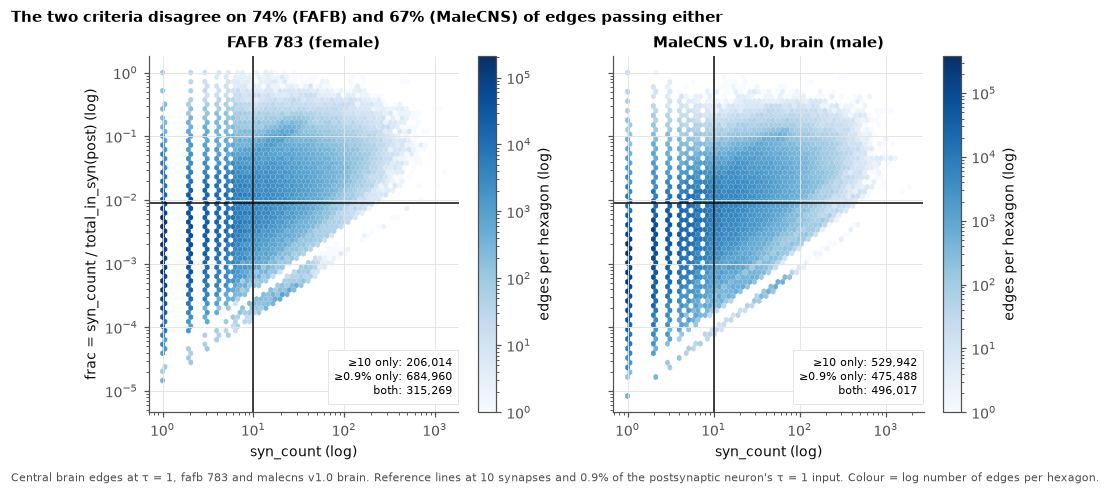

,fafb,malecns
abs_only,2.060e+05,5.299e+05
rel_only,6.850e+05,4.755e+05
both,3.153e+05,4.960e+05
neither,4.519e+06,7.151e+06
disagree_pct_of_all,1.556e+01,1.162e+01
disagree_pct_of_passing_either,7.386e+01,6.696e+01


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
N["B3"] = {}
for ax, (ds, (n, e)) in zip(axes, T.items()):
    c = restrict(e, population_ids(n, "central"))
    ct = eda_b.b3_crosstab(c); d = eda_b.b3_disagreement(c)
    N["B3"][ds] = d
    save_table(ct.reset_index(), f"B3_crosstab_{ds}_central.csv")
    display(ct)
    hb = ax.hexbin(c["syn_count"], c["frac"], xscale="log", yscale="log", gridsize=60, bins="log",
                   cmap="Blues", mincnt=1, linewidths=0)
    ax.axvline(10, color="#0b0b0b", lw=1); ax.axhline(0.009, color="#0b0b0b", lw=1)
    ax.set(xlabel="syn_count (log)", title=f"{LABELS[ds]}")
    ax.text(0.98, 0.04, f"≥10 only: {d['abs_only']:,}\n≥0.9% only: {d['rel_only']:,}\nboth: {d['both']:,}",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=7.5,
            bbox=dict(fc="white", ec="#e4e3df", lw=0.6))
    fig.colorbar(hb, ax=ax, label="edges per hexagon (log)")
axes[0].set_ylabel("frac = syn_count / total_in_syn(post) (log)")
fig.suptitle(f"The two criteria disagree on {N['B3']['fafb']['disagree_pct_of_passing_either']:.0f}% (FAFB) and "
             f"{N['B3']['malecns']['disagree_pct_of_passing_either']:.0f}% (MaleCNS) of edges passing either",
             x=0.0, ha="left", fontweight="bold", fontsize=10)
save(fig, "B3", ["fafb", "malecns"], "min10-frac0.009", ["central"],
     "Central brain edges at τ = 1, fafb 783 and malecns v1.0 brain. Reference lines at 10 synapses and 0.9% of the "
     "postsynaptic neuron's τ = 1 input. Colour = log number of edges per hexagon.")
plt.show()
pd.DataFrame(N["B3"]).round(2)

## B4 — Few edges carry most synapses

Central population, edges at τ = 1 sorted strongest first. Marker: where `syn_count` drops below 10.
Note: Schlegel et al. (2024) report 16% of edges / 79% of synapses for **type-level** edges; these curves are **neuron-level**.

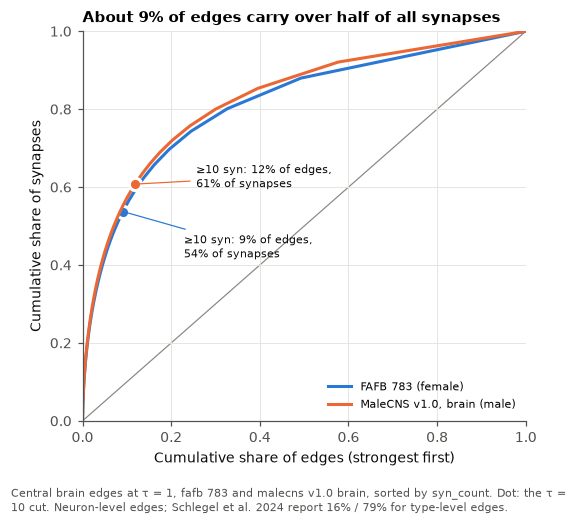

In [10]:
fig, ax = plt.subplots(figsize=(5.2, 4.6))
N["B4"] = {}
for ds, (n, e) in T.items():
    curve, mk = eda_b.b4_lorenz(restrict(e, population_ids(n, "central")))
    N["B4"][ds] = mk
    ax.plot(curve.cum_edges, curve.cum_synapses, color=COLORS[ds], label=LABELS[ds])
    ax.plot(mk["edges_share"], mk["synapses_share"], "o", ms=8, color=COLORS[ds], mec="white", mew=2)
    ax.annotate(f"≥10 syn: {mk['edges_share']:.0%} of edges,\n{mk['synapses_share']:.0%} of synapses",
                (mk["edges_share"], mk["synapses_share"]), xytext=(40, -30 if ds == "fafb" else -2),
                textcoords="offset points", fontsize=7.5, color="#0b0b0b",
                arrowprops=dict(arrowstyle="-", color=COLORS[ds], lw=0.8))
ax.plot([0, 1], [0, 1], color=COLORS["muted"], lw=0.8, zorder=0)
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Cumulative share of edges (strongest first)", ylabel="Cumulative share of synapses")
ax.legend(fontsize=7.5, loc="lower right")
ax.set_title(f"About {N['B4']['fafb']['edges_share']:.0%} of edges carry over half of all synapses", loc="left")
save(fig, "B4", ["fafb", "malecns"], "min1", ["central"],
     "Central brain edges at τ = 1, fafb 783 and malecns v1.0 brain, sorted by syn_count. Dot: the τ = 10 cut. "
     "Neuron-level edges; Schlegel et al. 2024 report 16% / 79% for type-level edges.")
plt.show()

## B5 — Left–right weight agreement (FAFB)

Type-level edges (Definitions), FAFB, central, τ = 10 (the item names no threshold). Pairs present on at least one side; Pearson R of log10 weights for pairs on both sides; share of those whose weights differ by more than 30% (larger / smaller > 1.3). τ = 1 is reported alongside as a sensitivity line.

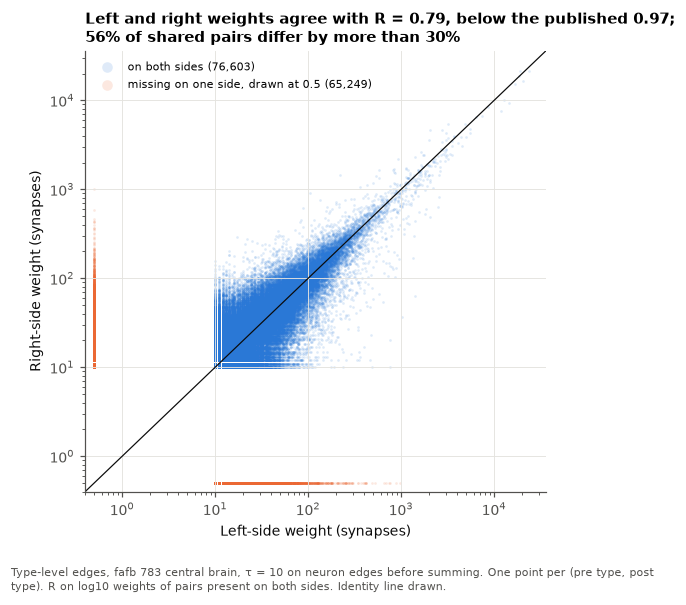

,tau10,tau1
pairs_either,141852.000,1.630e+06
pairs_both,76603.000,6.109e+05
only_a,26753.000,4.833e+05
only_b,38496.000,5.359e+05
pearson_r_log10,0.792,7.730e-01
share_diff_gt_30pct,0.563,6.830e-01
median_log2_b_over_a,0.107,0.000e+00


In [11]:
fn, fe = T["fafb"]
fc_ids = population_ids(fn, "central")
fn_c, fe_c = fn[fn.neuron_id.isin(fc_ids)], restrict(fe, fc_ids)
pairs5, s5 = eda_b.b5_left_right(fn_c, fe_c[fe_c.syn_count >= 10])
_, s5_t1 = eda_b.b5_left_right(fn_c, fe_c)
N["B5"] = {"tau10": s5, "tau1": s5_t1}
save_table(pairs5.reset_index(), "B5_type_pairs_fafb_central_min10.csv")

def pair_scatter(ax, both, stats, xlabel, ylabel):
    shared = both[(both.a > 0) & (both.b > 0)]
    one = both[(both.a == 0) | (both.b == 0)]
    ax.scatter(shared.a, shared.b, s=3, alpha=0.15, color=COLORS["fafb"], lw=0, rasterized=True,
               label=f"on both sides ({len(shared):,})")
    ax.scatter(one.a.replace(0, 0.5), one.b.replace(0, 0.5), s=3, alpha=0.15, color=COLORS["malecns"], lw=0,
               rasterized=True, label=f"missing on one side, drawn at 0.5 ({len(one):,})")
    lim = [0.4, both.max().max() * 1.5]
    ax.plot(lim, lim, color="#0b0b0b", lw=0.8)
    ax.set(xscale="log", yscale="log", xlim=lim, ylim=lim, xlabel=xlabel, ylabel=ylabel)
    ax.legend(fontsize=7.5, markerscale=4, loc="upper left")

fig, ax = plt.subplots(figsize=(5.4, 5.2))
pair_scatter(ax, pairs5, s5, "Left-side weight (synapses)", "Right-side weight (synapses)")
ax.set_title(f"Left and right weights agree with R = {s5['pearson_r_log10']:.2f}, below the published 0.97;\n"
             f"{s5['share_diff_gt_30pct']:.0%} of shared pairs differ by more than 30%", loc="left")
save(fig, "B5", ["fafb"], "min10", ["central"],
     "Type-level edges, fafb 783 central brain, τ = 10 on neuron edges before summing. One point per (pre type, post type). "
     "R on log10 weights of pairs present on both sides. Identity line drawn.")
plt.show()
pd.DataFrame(N["B5"]).round(3)

## B6 — Weight agreement across animals

Matched types (a fafb `cell_type` that appears verbatim in malecns `flywire_type`), right side, brain neurons of both datasets, τ = 10. Malecns neurons are labelled by their `flywire_type`. A shifted median log2 ratio is a technical offset between pipelines; spread beyond B5 is individual or sex difference.

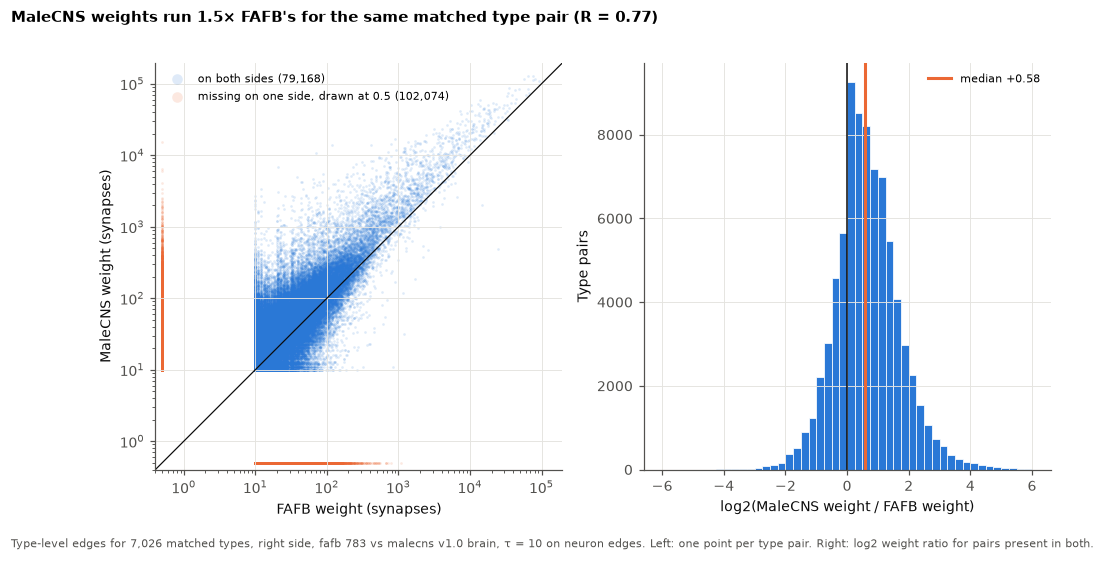

,tau10,tau1
pairs_either,181242.000,1.533e+06
pairs_both,79168.000,5.845e+05
only_a,23579.000,3.747e+05
only_b,78495.000,5.738e+05
pearson_r_log10,0.772,7.900e-01
share_diff_gt_30pct,0.721,7.550e-01
median_log2_b_over_a,0.585,5.850e-01
matched_types,7026.000,7.026e+03


In [12]:
mn, me = T["malecns"]
pairs6, s6 = eda_b.b6_across(fn, fe[fe.syn_count >= 10], mn, me[me.syn_count >= 10])
_, s6_t1 = eda_b.b6_across(fn, fe, mn, me)
N["B6"] = {"tau10": s6, "tau1": s6_t1}
save_table(pairs6.reset_index(), "B6_type_pairs_right_min10.csv")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.8))
pair_scatter(axes[0], pairs6, s6, "FAFB weight (synapses)", "MaleCNS weight (synapses)")
shared = pairs6[(pairs6.a > 0) & (pairs6.b > 0)]
lr = np.log2(shared.b / shared.a)
axes[1].hist(lr, bins=np.arange(-6, 6.25, 0.25), color=COLORS["fafb"], edgecolor="white", linewidth=0.5)
axes[1].axvline(0, color="#0b0b0b", lw=1)
axes[1].axvline(s6["median_log2_b_over_a"], color=COLORS["malecns"], lw=2, label=f"median {s6['median_log2_b_over_a']:+.2f}")
axes[1].set(xlabel="log2(MaleCNS weight / FAFB weight)", ylabel="Type pairs")
axes[1].legend(fontsize=7.5)
fig.suptitle(f"MaleCNS weights run {2**s6['median_log2_b_over_a']:.1f}× FAFB's for the same matched type pair "
             f"(R = {s6['pearson_r_log10']:.2f})", x=0.0, ha="left", fontweight="bold", fontsize=10)
save(fig, "B6", ["fafb", "malecns"], "min10", ["all", "right"],
     f"Type-level edges for {s6['matched_types']:,} matched types, right side, fafb 783 vs malecns v1.0 brain, τ = 10 on "
     "neuron edges. Left: one point per type pair. Right: log2 weight ratio for pairs present in both.")
plt.show()
pd.DataFrame(N["B6"]).round(3)

## B7 — Does magnitude dominate the features

FAFB, central. Raw-count columns: the four `basic_features` at τ = 10 plus input and output synapses per neuropil from edgeroi (all cached rows, the same τ = 1 basis as `total_in_syn`). Standardise, PCA, Pearson r of PC1–PC5 with log10(total_in_syn + total_out_syn); Spearman ρ alongside, because a few very large neurons dominate the standardised counts. Neurons with no synapses at all are left out (log undefined).

The second row is a **Project 2 contrast, not part of the EDA item**: the same PCA after each neuron's per-neuropil columns are divided by its own total (magnitude removed).

/Users/sdtkl12/Konya_Gıda_ve_Tarım/CENG8004/sa_project/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


/Users/sdtkl12/Konya_Gıda_ve_Tarım/CENG8004/sa_project/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


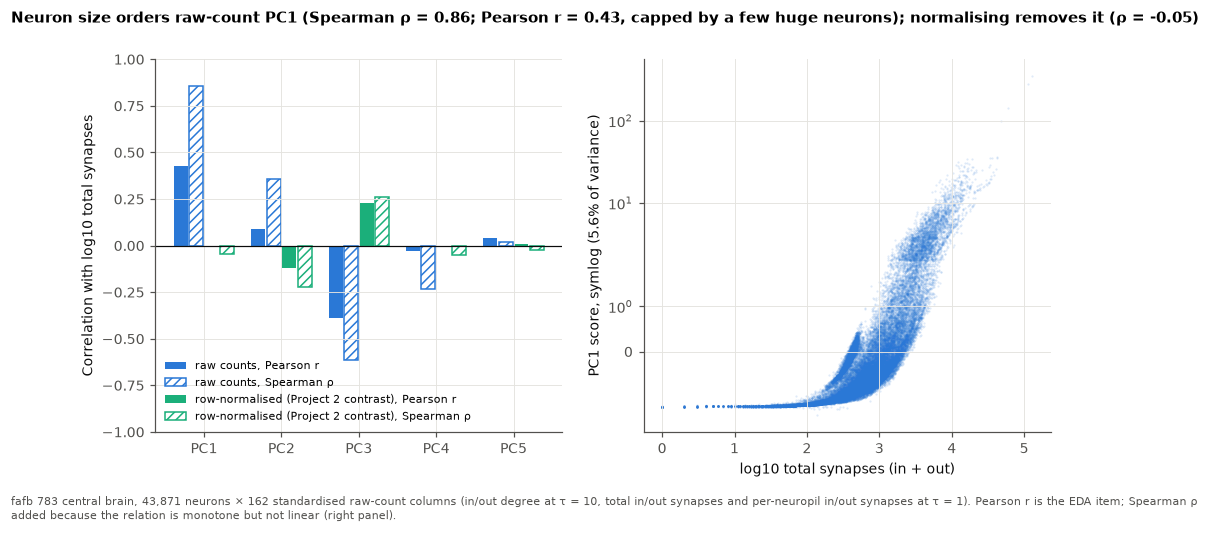

,component,r,spearman_rho,explained_variance,table
0,PC1,0.427,0.859,0.056,raw
1,PC2,0.090,0.356,0.040,raw
2,PC3,-0.388,-0.614,0.034,raw
3,PC4,-0.027,-0.233,0.024,raw
4,PC5,0.041,0.022,0.023,raw
0,PC1,-0.002,-0.047,0.036,normalised
1,PC2,-0.122,-0.224,0.034,normalised
2,PC3,0.227,0.260,0.024,normalised
3,PC4,-0.010,-0.048,0.021,normalised
4,PC5,0.009,-0.021,0.020,normalised


In [13]:
fe_roi = raw["fafb"][2]
X = eda_b.b7_raw_features(fn, fe, fe_roi, "central", tau=10)
r_raw, sc_raw, info = eda_b.b7_pca(X)
r_norm, _, info_n = eda_b.b7_pca(X, normalise_rows=True)
N["B7"] = {"raw": r_raw.round(4).to_dict("records"), "normalised_rows": r_norm.round(4).to_dict("records"),
           "info": info, "info_normalised": info_n}
save_table(r_raw.assign(table="raw").pipe(lambda d: pd.concat([d, r_norm.assign(table="normalised_rows")])),
           "B7_pc_size_correlation.csv")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4))
x = np.arange(5); w = 0.2
for i, (res, col, lab) in enumerate([(r_raw, COLORS["fafb"], "raw counts"), (r_norm, COLORS["third"], "row-normalised (Project 2 contrast)")]):
    axes[0].bar(x + (2 * i - 1.5) * w, res.r, width=w * 0.9, color=col, label=f"{lab}, Pearson r")
    axes[0].bar(x + (2 * i - 0.5) * w, res.spearman_rho, width=w * 0.9, color="white", edgecolor=col, hatch="////",
                lw=1, label=f"{lab}, Spearman ρ")
axes[0].axhline(0, color="#0b0b0b", lw=0.8)
axes[0].set(xticks=x, xticklabels=r_raw.component, ylim=(-1, 1), ylabel="Correlation with log10 total synapses")
axes[0].legend(fontsize=7, loc="lower left")
axes[1].scatter(sc_raw.log10_total_syn, sc_raw.PC1, s=2, alpha=0.15, color=COLORS["fafb"], lw=0, rasterized=True)
axes[1].set(yscale="symlog", xlabel="log10 total synapses (in + out)",
            ylabel=f"PC1 score, symlog ({r_raw.explained_variance[0]:.1%} of variance)")
fig.suptitle(f"Neuron size orders raw-count PC1 (Spearman ρ = {r_raw.spearman_rho[0]:.2f}; Pearson r = {r_raw.r[0]:.2f}, "
             f"capped by a few huge neurons); normalising removes it (ρ = {r_norm.spearman_rho[0]:+.2f})",
             x=0.0, ha="left", fontweight="bold", fontsize=10)
save(fig, "B7", ["fafb"], "min10", ["central"],
     f"fafb 783 central brain, {info['neurons']:,} neurons × {info['columns']} standardised raw-count columns "
     "(in/out degree at τ = 10, total in/out synapses and per-neuropil in/out synapses at τ = 1). "
     "Pearson r is the EDA item; Spearman ρ added because the relation is monotone but not linear (right panel).")
plt.show()
pd.concat([r_raw.assign(table="raw"), r_norm.assign(table="normalised")]).round(3)

## Numbers for the report

In [14]:
def _clean(o):
    if isinstance(o, dict): return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, list): return [_clean(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    return o
(ROOT / "reports" / "eda_B_numbers.json").write_text(json.dumps(_clean(N), indent=1))
print("wrote reports/eda_B_numbers.json")

wrote reports/eda_B_numbers.json
